# 4. Effective chemical potential, interaction, and tunnelling

**Author:** Aditya Banerjee  
**Thesis:** *Linear Anyon Model with Rydberg Atoms*, Universitat de Barcelona, 2026

The thesis reads the first and second addition energies from the diagonal bond Hamiltonian, then compares the engineered hopping magnitudes with the target model. This notebook follows those definitions before any additional diagonal compensation.

**Thesis source:** Sections 4.1–4.4, Eqs. (64)–(75), Figures 6–7. Descriptions below are adapted from these sections;
equation numbers refer to the thesis. **Code source:** [`amplitudes_vs_muU_thesis.py`](../scripts/amplitudes_vs_muU_thesis.py), [`mu_vs_A_over_U.py`](../scripts/mu_vs_A_over_U.py).

**Steps:** parameters → sideband sums → effective energies → amplitudes → ratios → original plot families.

Run the numbered sections from top to bottom. Longer derivations and implementation
comparisons are at the end. These are theoretical calculations, not experimental data.

## 1. Import libraries

In [1]:
%matplotlib inline
from pathlib import Path
from itertools import product
import numpy as np
from scipy.special import jv
import matplotlib.pyplot as plt
from IPython.display import display

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
# Run from the repository root or from notebooks/.
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "scripts").is_dir() and (p / "data").is_dir())
DATA = ROOT / "data"
SAVE_FIGURES = False
STYLE = {"font.size": 11}


def show_figure(fig, name):
    if SAVE_FIGURES:
        destination = ROOT / "notebook_outputs"
        destination.mkdir(exist_ok=True)
        fig.savefig(destination / f"{name}.png", dpi=160)
    display(fig)
    plt.close(fig)

## 2. Set the interaction and drive parameters

**Symbols used in the code**

| Thesis symbol | Code name | Meaning |
|---|---|---|
| $C_{ab}$ | `C00`, `C01`, … | Interaction-shift parameters |
| $\Omega_\alpha,\Omega_\beta$ | `Om_a`, `Om_b` | Laser-coupling amplitudes |
| $\omega'$ | `wp` or `WP` | Drive rate |
| $A$ | `A` | Detuning-modulation amplitude |
| $\kappa=A/\omega'$ | `kappa` or `kap` | Dimensionless modulation index |
| $L$ | `L` | Number of sites |
| $N$ | `N` | Total occupation quanta |

The bare pair energies are $2C_{00},C_{01},2C_{11},C_{02},C_{12},2C_{22}$.
The $C$, $\Omega$, $\omega'$, and $A$ values use one **native numerical rate unit**.
$J_\ell(\kappa)$ is the Bessel function of integer order $\ell$.

Evolution uses $K=H/(\hbar\omega_{\rm ref})$ and $\tau=\omega_{\rm ref}t$,
with $[\hbar\omega_{\rm ref}]={\rm J}$ and $[\tau]=1$; the reference is one
native rate unit. This preserves the source numbers without claiming a calibrated
microsecond axis while the cycles-versus-radians convention remains unresolved.

In [3]:
C00, C01, C11 = 0.0, 20.0, 15.0
C02 = 2.0 * C11
C12, C22 = 45.0, 55.0
wp = 40.0
N_RES = 1
nu = 2 * C11 - C02 - N_RES * wp
ells = np.arange(-80, 81)

D1 = 1.0 / (C01 - 2 * C00)
D2 = 1.0 / (2 * C11 - C01)
D3 = 1.0 / (C12 - C02)
K1 = abs(D1 - D2)
K2 = abs(D2 - D3)
A_ = 3 * D1 - D2
B_ = 4 * D1 + D3 - 2 * D2

KAPPAS = [0.8, 1.2, 2.0]
KMAIN = 1.2
COL = {0.8: "#7fb3d5", 1.2: "#12395e", 2.0: "#2e86c1"}
OM_A = 1.0  # Rabi scale (native rate unit); the curves slide as lam^2

## 3. Evaluate the two sideband sums

The source defines
$$\Sigma=\sum_\ell\frac{J_\ell(\kappa)^2}{C_{02}-C_{01}+\widetilde\nu+\ell\omega'},\qquad
\Sigma_4=\sum_\ell J_\ell(\kappa)^2\left[
\frac1{C_{12}-2C_{11}+\widetilde\nu+\ell\omega'}-
\frac1{2C_{22}-C_{12}+\widetilde\nu+\ell\omega'}\right].$$
Both have inverse-rate units. The source functions below evaluate the finite sums.

In [4]:
def Sigma(k):
    return float(np.sum(jv(ells, k) ** 2 / (C02 - C01 + nu + ells * wp)))


def Sigma4(k):
    return float(
        np.sum(
            jv(ells, k) ** 2
            * (1.0 / (C12 - 2 * C11 + nu + ells * wp) - 1.0 / (2 * C22 - C12 + nu + ells * wp))
        )
    )

## 4. Define the effective chemical potential and interaction

Following thesis Eq. (65),
$$\mu_{\rm eff}=E_{01}-E_{00},\qquad U_{\rm eff}=E_{02}-2E_{01}+E_{00}.$$
With $r=\Omega_\beta^2/\Omega_\alpha^2$, $x=r\Sigma$,
$a=3D_1-D_2$, $b=4D_1+D_3-2D_2$, and $D_i$ the inverse denominators,
$$\mu_{\rm eff}=\Omega_\alpha^2(a-x),\quad
U_{\rm eff}=\Omega_\alpha^2(3x-b),\quad
\frac{\mu_{\rm eff}}{U_{\rm eff}}=\frac{a-x}{3x-b}.$$
The source uses a positive **addition cost** $+\mu N$; the usual $-\mu N$ convention has the opposite sign.

In [5]:
def muU_x(x):
    return (A_ - x) / (3.0 * x - B_)

## 5. Calculate the tunnelling magnitudes

Thesis Eq. (75) gives
$$A_1=\Omega_\alpha^2|D_1-D_2|,\quad
A_2=A_3=\Omega_\alpha\Omega_\beta|D_2-D_3|\,|J_m(\kappa)|,\quad
A_4=\Omega_\beta^2|\Sigma_4|.$$
Here $A_i$ are nonnegative magnitudes, $m$ is the resonance order, and
the source function returns their ratios to $U_{\rm eff}$, together with the chemical potential.

In [6]:
def curves(k, r):
    """A_i/U_eff (4), mu_eff/U_eff, mu_eff [native rate unit] at Om_a = OM_A."""
    S, S4 = Sigma(k), Sigma4(k)
    x = r * S
    den = 3.0 * x - B_
    a1 = K1 / den
    a2 = np.sqrt(r) * K2 * abs(jv(N_RES, k)) / den
    a4 = r * abs(S4) / den
    mu_over_U = (A_ - x) / den
    mu = OM_A**2 * (A_ - x)
    return (a1, a2, a2, a4), mu_over_U, mu

The small display adapter below names the source outputs. It also evaluates the unnormalized magnitudes directly, so no division by zero is needed when $U_{\rm eff}=0$.

In [7]:
def evaluate_parameters(kappa, r):
    r = np.asarray(r, dtype=float)
    normalized, ratio, mu = curves(kappa, r)
    interaction = OM_A**2 * (3 * r * Sigma(kappa) - B_)
    magnitudes = OM_A**2 * np.array(
        [
            np.full_like(r, K1),
            np.sqrt(r) * K2 * abs(jv(N_RES, kappa)),
            np.sqrt(r) * K2 * abs(jv(N_RES, kappa)),
            r * abs(Sigma4(kappa)),
        ]
    )
    return {
        "mu": mu,
        "U": interaction,
        "amplitudes": magnitudes,
        "mu_over_U": ratio,
        "amplitudes_over_U": np.asarray(normalized),
    }


r = np.linspace(0, 4, 401)
kappas = KAPPAS
families = {k: evaluate_parameters(k, r) for k in kappas}
reference = evaluate_parameters(KMAIN, np.array([1.0]))
print("At Omega_a=Omega_b=1, kappa=1.2:")
for key in ["mu", "U", "amplitudes", "mu_over_U"]:
    print(key, reference[key])

At Omega_a=Omega_b=1, kappa=1.2:
mu [0.04345]
U [-0.047016]
amplitudes [[0.05   ]
 [0.01661]
 [0.01661]
 [0.01012]]
mu_over_U [-0.924143]


## 6. Plot the parameters against the laser-intensity ratio

The dimensionless control is $r=\Omega_\beta^2/\Omega_\alpha^2$.
The zero of $U_{\rm eff}$ separates attraction from repulsion in this formula family.
Here $0\leq r\leq4$ at $\Omega_\alpha=1$, so the larger coupling can reach two native units;
the nominal largest coupling-to-denominator ratio is 0.2, not a proof of perturbative accuracy.

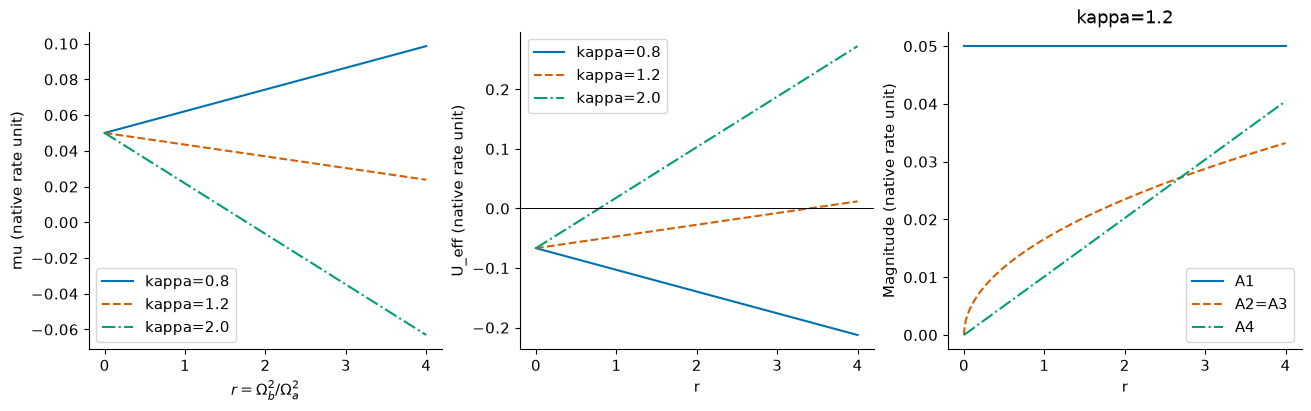

In [8]:
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
    colours, styles = ["#0072B2", "#D55E00", "#009E73"], ["-", "--", "-."]
    for k, colour, style in zip(kappas, colours, styles):
        result = families[k]
        axes[0].plot(r, result["mu"], color=colour, linestyle=style, label=f"kappa={k}")
        axes[1].plot(r, result["U"], color=colour, linestyle=style, label=f"kappa={k}")
    for i, colour, style, label in zip([0, 1, 3], colours, styles, ["A1", "A2=A3", "A4"]):
        axes[2].plot(r, families[1.2]["amplitudes"][i], color=colour, linestyle=style, label=label)
    axes[0].set(xlabel=r"$r=\Omega_b^2/\Omega_a^2$", ylabel="mu (native rate unit)")
    axes[1].set(xlabel="r", ylabel="U_eff (native rate unit)")
    axes[1].axhline(0, color="black", linewidth=0.7)
    axes[2].set(xlabel="r", ylabel="Magnitude (native rate unit)", title="kappa=1.2")
    for ax in axes:
        ax.legend()
    show_figure(fig, "04_parameters_and_amplitudes")

## 7. Keep the two sides of the pole separate

At $3x=b$, $U_{\rm eff}=0$ and its normalized ratios are undefined.
We split the sampled curves into constant-sign-$U_{\rm eff}$ branches.
The formal large-$|x|$ limit is $-1/3$; this algebraic limit does not validate arbitrarily strong driving.

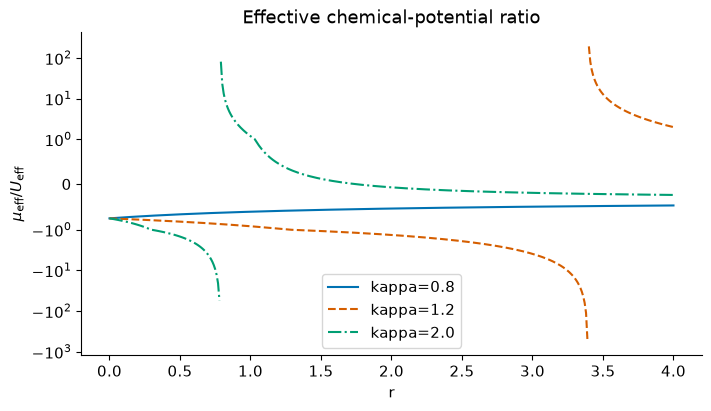

In [9]:
with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
    for k, colour, style in zip(kappas, colours, styles):
        result = families[k]
        signs = np.sign(result["U"])
        splits = np.flatnonzero(np.diff(signs) != 0) + 1
        for index, branch in enumerate(np.split(np.arange(len(r)), splits)):
            ax.plot(
                r[branch],
                result["mu_over_U"][branch],
                color=colour,
                linestyle=style,
                label=f"kappa={k}" if index == 0 else None,
            )
    ax.set_yscale("symlog", linthresh=1)
    ax.set(
        xlabel="r",
        ylabel=r"$\mu_{\rm eff}/U_{\rm eff}$",
        title="Effective chemical-potential ratio",
    )
    ax.legend()
    show_figure(fig, "04_ratio_branches")

## 8. Reproduce the amplitude-versus-ratio plot family

As in `amplitudes_vs_muU_thesis.py`, vary $\Omega_\alpha$ for $A_1$
and vary $\Omega_\beta$ for the other panels. The titles state what is fixed.
**Notebook adaptation:** both couplings are restricted to at most one native unit;
these are bounded subsets of the original algebraic curves.

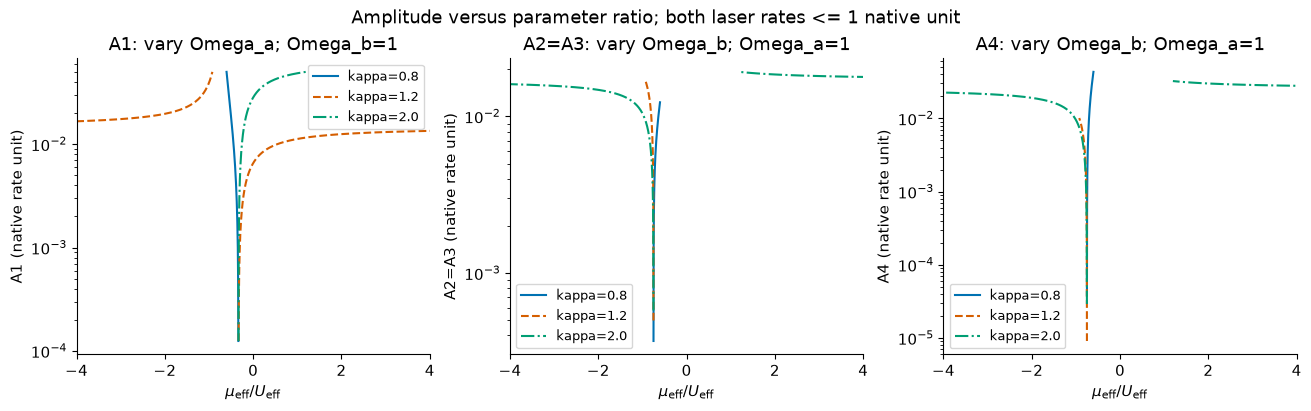

Amplitude-family sweep: 1200 samples per curve; separate branches at U_eff=0.


In [10]:
def signed_branches(interaction):
    cuts = np.flatnonzero(np.diff(np.sign(interaction)) != 0) + 1
    return [b for b in np.split(np.arange(len(interaction)), cuts) if len(b) > 1]


channels = [(0, "A1"), (1, "A2=A3"), (3, "A4")]
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
    for ax, (channel, label) in zip(axes, channels):
        if channel == 0:
            omega_a = np.geomspace(0.05, 1.0, 1200)
            omega_b = np.ones_like(omega_a)
            sweep_label = "vary Omega_a; Omega_b=1"
        else:
            omega_b = np.geomspace(0.03, 1.0, 1200)
            omega_a = np.ones_like(omega_b)
            sweep_label = "vary Omega_b; Omega_a=1"
        for kappa, colour, style in zip(kappas, colours, styles):
            values = evaluate_parameters(kappa, (omega_b / omega_a) ** 2)
            for j, branch in enumerate(signed_branches(values["U"])):
                ax.plot(
                    values["mu_over_U"][branch],
                    (omega_a**2 * values["amplitudes"][channel])[branch],
                    color=colour,
                    linestyle=style,
                    label=f"kappa={kappa}" if j == 0 else None,
                )
        ax.set_yscale("log")
        ax.set(
            xlabel=r"$\mu_{\rm eff}/U_{\rm eff}$",
            ylabel=f"{label} (native rate unit)",
            xlim=(-4, 4),
            title=f"{label}: {sweep_label}",
        )
        ax.legend(fontsize=9)
    fig.suptitle("Amplitude versus parameter ratio; both laser rates <= 1 native unit")
    show_figure(fig, "04_amplitudes_vs_mu_over_U")
print("Amplitude-family sweep: 1200 samples per curve; separate branches at U_eff=0.")

## 9. Plot chemical potential against normalized amplitudes

This follows `mu_vs_A_over_U.py` at fixed $\Omega_\alpha=1$.
The horizontal ratios are dimensionless; the vertical chemical potential retains a native rate unit.
The teaching range $10^{-3}\leq r\leq1$ keeps $\Omega_\beta\leq1$.

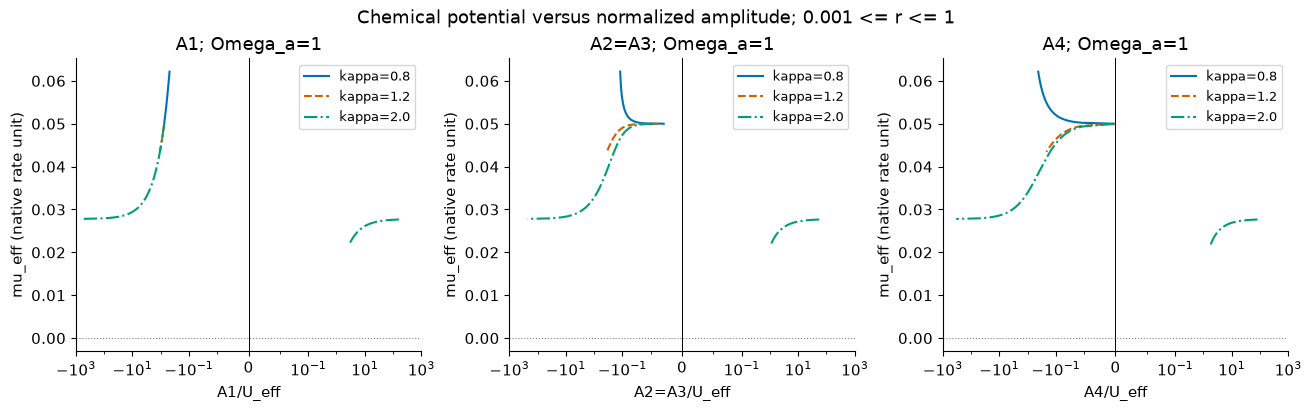

Chemical-potential-family sweep: bounded Omega_a=1 and Omega_b<=1.


In [11]:
bounded_r = np.geomspace(1e-3, 1.0, 1200)
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
    for ax, (channel, label) in zip(axes, channels):
        for kappa, colour, style in zip(kappas, colours, styles):
            values = evaluate_parameters(kappa, bounded_r)
            for j, branch in enumerate(signed_branches(values["U"])):
                ax.plot(
                    values["amplitudes_over_U"][channel, branch],
                    values["mu"][branch],
                    color=colour,
                    linestyle=style,
                    label=f"kappa={kappa}" if j == 0 else None,
                )
        ax.set_xscale("symlog", linthresh=1e-2)
        ax.set_xticks([-1000, -10, -0.1, 0, 0.1, 10, 1000])
        ax.set_xlim(-1000, 1000)
        ax.axvline(0, color="black", linewidth=0.7)
        ax.axhline(0, color="gray", linestyle=":", linewidth=0.8)
        ax.set(
            xlabel=f"{label}/U_eff", ylabel="mu_eff (native rate unit)", title=f"{label}; Omega_a=1"
        )
        ax.legend(fontsize=9)
    fig.suptitle("Chemical potential versus normalized amplitude; 0.001 <= r <= 1")
    show_figure(fig, "04_mu_vs_amplitude_over_U")
print("Chemical-potential-family sweep: bounded Omega_a=1 and Omega_b<=1.")

## 10. Read the result and check the limits

The locked-resonance family has $A_2=A_3$ in magnitude.
When $r=0$, $\mu/U=-a/b$; when both Rabi amplitudes scale by a factor $s$,
all dimensional rates scale as $s^2$ and their ratios are unchanged.
Equal hopping magnitudes alone do not match every diagonal or phase condition of the full target model.

In [12]:
assert np.allclose(reference["amplitudes"][1], reference["amplitudes"][2])
assert np.isclose(muU_x(0), -A_ / B_)
print("A2=A3 and r=0 ratio:", muU_x(0))
for k in KAPPAS:
    pole_r = B_ / (3 * Sigma(k))
    print(
        f"kappa={k}: Sigma={Sigma(k):+.6f}; pole at r={pole_r:.4f}"
        if pole_r >= 0
        else f"kappa={k}: no pole at nonnegative r"
    )

A2=A3 and r=0 ratio: -0.7500000000000004
kappa=0.8: no pole at nonnegative r
kappa=1.2: Sigma=+0.006550; pole at r=3.3927
kappa=2.0: Sigma=+0.028274; pole at r=0.7860


## Appendix — detailed derivations and verification

The main calculation is complete. This appendix retains the symbolic steps, conventions, limiting cases, and source comparisons for closer study.

### Conventions, dimensions, and evidence status

**Theoretical model:** each site has the orthonormal occupation basis
$|0\rangle,|1\rangle,|2\rangle$. The tensor-product basis is lexicographic,
with the leftmost site the most significant index. Occupations above two are
excluded. State vectors have norm one; probabilities and occupation numbers
are dimensionless. Chains use open boundaries unless explicitly stated.
This is a nonrelativistic finite-dimensional calculation; no spacetime metric
signature is used. Finite sums replace spatial integration, and no continuum
boundary conditions are assumed.

Start with physical energy $H$ and positive reference angular frequency
$\omega_{\rm ref}$. Define
$$K=\frac{H}{\hbar\omega_{\rm ref}},\qquad
  \tau=\omega_{\rm ref}t,\qquad \hbar=\frac{h}{2\pi}.$$
Since $[H]={\rm J}$ and $[\hbar\omega_{\rm ref}]={\rm J\,s}\,{\rm s}^{-1}
={\rm J}$, $K$ is dimensionless. Likewise $[\tau]={\rm s}^{-1}{\rm s}=1$.
Schrödinger evolution becomes
$$i\hbar\,\omega_{\rm ref}\frac{d\psi}{d\tau}
   =\hbar\omega_{\rm ref}K\psi,
  \qquad i\frac{d\psi}{d\tau}=K\psi.$$

**Unresolved source convention:** archived scripts label numerical rates as
MHz while using the numerical matrix in $\exp(-iEt)$; a header also equates MHz with rad/us.
Appendix B of the thesis writes $\omega'/2\pi$ in MHz. If a matrix is supplied
as $H/h$ in cycles per unit time, its propagator is $\exp[-i2\pi(H/h)t]$;
if supplied as $H/\hbar$, it is $\exp[-i(H/\hbar)t]$. Dimensional analysis
cannot distinguish these two conventions. The notebooks therefore preserve
native numerical values and use $\tau$, without claiming a calibrated
microsecond axis. Any physical conversion requires a declared convention.
For the effective-model numerical cells, the reference is one native rate
unit: a rate divided by that reference has the same numerical value.
Thus the arrays used in the propagator are dimensionless $K$, even when
the source-formula coefficients are described below as native rates.

**Source-backed numerical facts** refer to the archived files and checks
shown here. They are not experimental observations. **Physical reachability**
and **proposed extensions** are labelled separately. See
[scientific notes](../SCIENTIFIC_NOTES.md) for unresolved interpretations.

### 4.1 Definitions with their dimensions

The $C_{ab}$ interaction shifts and the real laser-coupling
amplitudes $\Omega_a,\Omega_b$ use the normalization in Notebook 1.
The drive has modulation amplitude $A$, rate $\omega'$, and dimensionless
index $\kappa=A/\omega'$. Its common detuning offset is
$\widetilde\nu=2C_{11}-C_{02}-m\omega'$ for integer resonance order $m$.
$J_\ell$ denotes the Bessel function of the first kind. In code, each
sideband sum runs from $-\ell_{\max}$ to $+\ell_{\max}$; convergence must
be checked by increasing that cutoff.

Define the inverse-rate quantities
$$D_1=(C_{01}-2C_{00})^{-1},\quad D_2=(2C_{11}-C_{01})^{-1},\quad
  D_3=(C_{12}-C_{02})^{-1},$$
$$a=3D_1-D_2,\qquad b=4D_1+D_3-2D_2.$$
Define the dimensionless intensity ratio
$r=\Omega_b^2/\Omega_a^2\geq0$ with $\Omega_a\neq0$, and let
$$\Sigma(\kappa)=\sum_\ell\frac{J_\ell(\kappa)^2}
      {C_{02}-C_{01}+\widetilde\nu+\ell\omega'},\qquad x=r\Sigma(\kappa).$$
Both $x$ and $a,b$ have inverse-rate dimensions. To derive the
effective quantities, use three uncompensated bond diagonal rates:
$$\epsilon_{00}=-2\Omega_a^2D_1,\quad
 \epsilon_{01}=\Omega_a^2(D_1-D_2)-\Omega_b^2\Sigma,\quad
 \epsilon_{02}=\Omega_b^2\Sigma-\Omega_a^2D_3.$$
The source uses the **plus-cost** convention
$\mu_{\rm eff}=\epsilon_{01}-\epsilon_{00}$: positive $\mu_{\rm eff}$
means that adding the first occupation quantum costs energy. It would
correspond to the negative of a chemical potential written as $-\mu N$.
Subtract the diagonals explicitly:
$$\mu_{\rm eff}=\Omega_a^2(D_1-D_2)-\Omega_b^2\Sigma+2\Omega_a^2D_1
 =\Omega_a^2(3D_1-D_2)-\Omega_b^2\Sigma.$$
The second-addition excess is
$$U_{\rm eff}=\epsilon_{02}-2\epsilon_{01}+\epsilon_{00}$$
$$=\Omega_b^2\Sigma-\Omega_a^2D_3
 -2\Omega_a^2(D_1-D_2)+2\Omega_b^2\Sigma-2\Omega_a^2D_1$$
$$=\Omega_a^2(-4D_1+2D_2-D_3)+3\Omega_b^2\Sigma.$$
Substitute $\Omega_b^2=r\Omega_a^2$, $a=3D_1-D_2$,
$b=4D_1+D_3-2D_2$, and $x=r\Sigma$ to obtain
$$\mu_{\rm eff}=\Omega_a^2(a-x),\qquad
  U_{\rm eff}=\Omega_a^2(3x-b).$$
Each right-hand side has rate dimensions. Dividing cancels the common scale:
$$\frac{\mu_{\rm eff}}{U_{\rm eff}}
   =\frac{\Omega_a^2(a-x)}{\Omega_a^2(3x-b)}
   =\frac{a-x}{3x-b},\qquad 3x-b\neq0.$$
This is a ratio of rates, so it is dimensionless.

### 4.2 Magnitudes and why their signs are treated separately

Let
$$\Sigma_4=\sum_\ell J_\ell(\kappa)^2\left[
  \frac1{C_{12}-2C_{11}+\widetilde\nu+\ell\omega'}-
  \frac1{2C_{22}-C_{12}+\widetilde\nu+\ell\omega'}\right].$$
The four positive or zero magnitudes are
$$A_1=\Omega_a^2|D_1-D_2|,$$
$$A_2=A_3=\Omega_a^2\sqrt r\,|D_2-D_3|\,|J_m(\kappa)|,$$
$$A_4=\Omega_a^2r|\Sigma_4|.$$
Magnitudes have the same rate units as $U_{\rm eff}$. A ratio $A_i/U_{\rm eff}$
can be negative when $U_{\rm eff}<0$, even though $A_i\geq0$. Taking absolute
values here loses the hopping sign information; the Hamiltonian notebooks
therefore use the signed rates instead.

### 4.3 Poles and limiting cases

Provided $b\neq0$,
$$\left.\frac{\mu_{\rm eff}}{U_{\rm eff}}\right|_{x=0}=-\frac ab.$$
For large nonzero $x$, divide numerator and denominator by $x$:
$$\frac{a-x}{3x-b}=\frac{a/x-1}{3-b/x}
     \longrightarrow -\frac13.$$
This is a formal algebraic limit. Reaching arbitrarily large $r$ at fixed
$\Omega_a$ can violate the dispersive approximation, so the limit is not an
experimentally validated operating regime.

At $x=b/3$, $U_{\rm eff}=0$. If $a-b/3\neq0$ the ratio has a pole.
If $a=b/3$, the common zero instead cancels away from $x=b/3$, giving
$-1/3$, while the original $0/0$ ratio remains undefined at that point.
Whether the pole occurs for physical $r\geq0$ depends on the sign and possible
zero of $\Sigma$; $x$ is not an independently adjustable unrestricted input.

To plot the ratio without drawing a false line through its pole, split the
samples into constant-sign-$U_{\rm eff}$ branches. Never connect the two
branches with a line or replace the singular value by zero.

### 4.4 Overall drive scaling

Scale both Rabi rates by the same real factor $s$ while keeping the detunings,
$\kappa$, and $r$ fixed. Each expression contains exactly two Rabi-rate
factors, hence
$$\mu'_{\rm eff}=s^2\mu_{\rm eff},\quad U'_{\rm eff}=s^2U_{\rm eff},
  \quad A_i'=s^2A_i.$$
For $s\neq0$ and $U_{\rm eff}\neq0$, their ratios are unchanged. Larger $s$
also increases $|\Omega/\Delta|$, so this scaling identity does not extend
the validity of the second-order approximation.

### Compare the notebook calculation with the validated reference

The following cell is an implementation check. The main calculation above contains its own code and does not require these reference imports.

In [13]:
import sys

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from anyon_thesis.models import parameter_curves

for k in KAPPAS:
    visible = evaluate_parameters(k, r)
    reference_values = parameter_curves(k, r)
    for key in ["mu", "U", "amplitudes", "mu_over_U", "amplitudes_over_U"]:
        np.testing.assert_allclose(visible[key], reference_values[key], atol=1e-11)
print("Visible source formulas agree with the validated reference: PASS")

Visible source formulas agree with the validated reference: PASS


### Sources and adaptations

- [Read the thesis](https://hdl.handle.net/2445/231684); thesis equation numbers are identified beside their use.
- Original calculation code: [`amplitudes_vs_muU_thesis.py`](../scripts/amplitudes_vs_muU_thesis.py), [`mu_vs_A_over_U.py`](../scripts/mu_vs_A_over_U.py), source commit `22959963191fcbc4d283ec4b272b506ad6dd979b`.
- [Scientific notes](../SCIENTIFIC_NOTES.md): frequency convention, imposed compensation, physical phase reachability, and finite-size interpretation.
- [Validation and adaptation record](VALIDATION.md).
- Notebook layout follows the short, numbered explanation–code–output pattern of the
  [AQI example](https://github.com/Charub17/global-air-pollution-aqi-ml/blob/main/Global_Air_Pollution_AQI_ML.ipynb).
  Its prose, data analysis, and numerical claims are not reused.

The code cells retain the source calculations. Notebook-specific adaptations are
labelled beside the relevant cell. No large archived job is launched implicitly.